In [48]:
import pandas as pd
from scipy.stats import wilcoxon
import numpy as np
from scipy import stats

In [58]:
headers = ["Model", "Dataset","Variate", "Lookback", "PredLength", "Seed", "MSE", "MAE"]

mod1 = pd.read_csv("Result_00.csv", sep="-", header=None, names=headers) #beta=0.0
mod2 = pd.read_csv("Result_05.csv", sep="-", header=None, names=headers) #beta=0.5
mod3 = pd.read_csv("Result_08.csv", sep="-", header=None, names=headers) #beta=0.8
mod4 = pd.read_csv("Result_nobeta.csv", sep="-", header=None, names=headers) #beta=None
mod5 = pd.read_csv("Result_Chronos2_Vera.csv", sep="-", header=None, names=headers) #Adaptive
mod6 = pd.read_csv("Result_Chronos2.csv", sep="-", header=None, names=headers)


In [59]:
def setup(df):
    raw2 = df.copy()
    raw2["Seed"] = raw2["Seed"].apply(lambda x: x.replace("seed", ""))
    raw2["Lookback"] = raw2["Lookback"].apply(lambda x: x.replace("sl", ""))
    raw2["PredLength"] = raw2["PredLength"].apply(lambda x: x.replace("pl", ""))
    raw2["MSE"] = raw2["MSE"].apply(lambda x: x.replace("mse:", ""))
    raw2["MAE"] = raw2["MAE"].apply(lambda x: x.replace("mae:", ""))


    raw2["Seed"] = raw2["Seed"].astype(int)
    raw2["Lookback"] = raw2["Lookback"].astype(int)
    raw2["PredLength"] = raw2["PredLength"].astype(int)
    raw2["MSE"] = raw2["MSE"].astype(float)
    raw2["MAE"] = raw2["MAE"].astype(float)
    return raw2


# dlinear_results = setup(DLinear)
mod1 = setup(mod1)
mod2 = setup(mod2)
mod3 = setup(mod3)
mod4 = setup(mod4)
mod5 = setup(mod5)
mod6 = setup(mod6)



In [60]:
datasets = ["ETTh1", "ETTh2", "ETTm1", "ETTm2"]

mod1 = mod1[mod1["Dataset"].isin(datasets)].sort_values(by=["Dataset", "PredLength", "Seed"])
mod2 = mod2[mod2["Dataset"].isin(datasets)].sort_values(by=["Dataset", "PredLength", "Seed"])

In [61]:
mod1.shape == mod2.shape

True

In [64]:
# Mean and Standard Deviation for MSE and MAE for Lookback 336 for 5 different seeds
mod1_tab = mod1.groupby(["Dataset", "PredLength"]).agg({"MSE": ["mean", "std"], "MAE": ["mean", "std", "count"]})
mod2_tab = mod2.groupby(["Dataset", "PredLength"]).agg({"MSE": ["mean", "std"], "MAE": ["mean", "std", "count"]})
mod3_tab = mod3.groupby(["Dataset", "PredLength"]).agg({"MSE": ["mean", "std"], "MAE": ["mean", "std", "count"]})
mod4_tab = mod4.groupby(["Dataset", "PredLength"]).agg({"MSE": ["mean", "std"], "MAE": ["mean", "std", "count"]})
mod5_tab = mod5.groupby(["Dataset", "PredLength"]).agg({"MSE": ["mean", "std"], "MAE": ["mean", "std", "count"]})
mod6_tab = mod6.groupby(["Dataset", "PredLength"]).agg({"MSE": ["mean", "std"], "MAE": ["mean", "std", "count"]})


In [65]:
mod6_tab

MSE            MAE           
                        mean  std      mean  std count
Dataset PredLength                                    
ELT     48          0.109591  0.0  0.195996  0.0     3
        96          0.129247  0.0  0.213615  0.0     3
        192         0.147858  0.0  0.230820  0.0     3
        336         0.180912  0.0  0.259542  0.0     3
        512         0.202412  0.0  0.277710  0.0     3
        720         0.235644  0.0  0.300379  0.0     3
ETTh1   48          0.393520  0.0  0.390808  0.0     3
        96          0.451758  0.0  0.432550  0.0     3
        192         0.514651  0.0  0.479177  0.0     3
        336         0.559915  0.0  0.511032  0.0     3
        512         0.575314  0.0  0.538458  0.0     3
        720         0.798661  0.0  0.636232  0.0     3
ETTh2   48          0.144641  0.0  0.252606  0.0     3
        96          0.187558  0.0  0.285432  0.0     3
        192         0.227363  0.0  0.324593  0.0     3
        336         0.230620  0.0  0.331679  0.0     3
        512         0.287970  0.0  0.369367  0.0     3
        720         0.325781  0.0  0.387740  0.0     3
ETTm1   48          0.363408  0.0  0.344156  0.0     3
        96          0.385706  0.0  0.363467  0.0     3
        192         0.456047  0.0  0.412625  0.0     3
        336         0.475089  0.0  0.429465  0.0     3
        512         0.481689  0.0  0.448853  0.0     3
        720         0.600612  0.0  0.497060  0.0     3
ETTm2   48          0.097390  0.0  0.196575  0.0     3
        96          0.116134  0.0  0.220263  0.0     3
        192         0.159761  0.0  0.260951  0.0     3
        336         0.204347  0.0  0.295414  0.0     3
        512         0.208108  0.0  0.302754  0.0     3
        720         0.370410  0.0  0.382682  0.0     3
METRLA  48          0.989943  0.0  0.466435  0.0     3
        96          1.342951  0.0  0.597905  0.0     3
        192         1.924962  0.0  0.771344  0.0     3
        336         1.738005  0.0  0.709638  0.0     3
        512         2.955942  0.0  1.054500  0.0     3
        720         1.915827  0.0  0.869565  0.0     3
PEMSBAY 48          0.617159  0.0  0.344157  0.0     3
        96          1.184150  0.0  0.505148  0.0     3
        192         1.233040  0.0  0.536366  0.0     3
        336         0.901012  0.0  0.439681  0.0     3
        512         1.137745  0.0  0.528453  0.0     3
        720         1.173079  0.0  0.536943  0.0     3
SOLAL   48          0.084317  0.0  0.114626  0.0     3
        96          0.127657  0.0  0.147356  0.0     3
        192         0.167539  0.0  0.181779  0.0     3
        336         0.197136  0.0  0.199559  0.0     3
        512         0.209729  0.0  0.210751  0.0     3
        720         0.233393  0.0  0.225277  0.0     3
SOLTX   48          0.081881  0.0  0.115177  0.0     3
        96          0.129642  0.0  0.155348  0.0     3
        192         0.144629  0.0  0.169539  0.0     3
        336         0.144924  0.0  0.166712  0.0     3
        512         0.146003  0.0  0.170186  0.0     3
        720         0.154903  0.0  0.177317  0.0     3
WTH     48          0.128983  0.0  0.137111  0.0     3
        96          0.167499  0.0  0.179793  0.0     3
        192         0.219099  0.0  0.231191  0.0     3
        336         0.341022  0.0  0.293240  0.0     3
        512         0.325521  0.0  0.306209  0.0     3
        720         0.375832  0.0  0.359263  0.0     3

In [63]:
A = mod1_tab[("MSE", "mean")]
B = mod6_tab[("MSE", "mean")]

diffs = A - B

d = np.mean(diffs) / np.std(diffs, ddof=1)
print(f"Cohen's d (paired): {d:.4f}")

n = len(diffs)
res = wilcoxon(A, B, alternative="greater")
r = 1 - (2 * res.statistic) / (n * (n + 1))
print(f"Rank-biserial r: {r:.4f}")

wilcoxon(A, B, alternative="greater")

NameError: name 'mod6_tab' is not defined

In [36]:
A = mod2_tab[("MSE", "mean")]
B = mod5_tab[("MSE", "mean")]

stats.ttest_ind(A, B)

TtestResult(statistic=np.float64(0.009838227658174976), pvalue=np.float64(0.9922078584061618), df=np.float64(34.0))

In [44]:
import numpy as np

preds = np.load("preds96.npy")
trues = np.load("trues96.npy")

In [45]:
preds.shape, trues.shape

((3484, 7), (3484, 7))

In [47]:
for i in range(preds.shape[1]):
    print(f"Preds' mean and variance {i}: {np.mean(preds[:,i])} and {np.var(preds[:,i])}")
    print(f"Trues' mean and variance {i}: {np.mean(preds[:,i])} and {np.var(trues[:,i])}\n")


Preds' mean and variance 0: -0.9679426550865173 and 0.4128987193107605
Trues' mean and variance 0: -0.9679426550865173 and 0.5267582535743713

Preds' mean and variance 1: -1.1540851593017578 and 0.16437694430351257
Trues' mean and variance 1: -1.1540851593017578 and 0.35926324129104614

Preds' mean and variance 2: -0.4172675609588623 and 0.10604459792375565
Trues' mean and variance 2: -0.4172675609588623 and 0.18338696658611298

Preds' mean and variance 3: -0.8986077308654785 and 0.36706268787384033
Trues' mean and variance 3: -0.8986077308654785 and 0.5746615529060364

Preds' mean and variance 4: -1.5348511934280396 and 0.18934722244739532
Trues' mean and variance 4: -1.5348511934280396 and 0.19473613798618317

Preds' mean and variance 5: 0.0001591866894159466 and 0.009363069199025631
Trues' mean and variance 5: 0.0001591866894159466 and 0.012709297239780426

Preds' mean and variance 6: -0.9297715425491333 and 0.4558536410331726
Trues' mean and variance 6: -0.9297715425491333 and 0.57

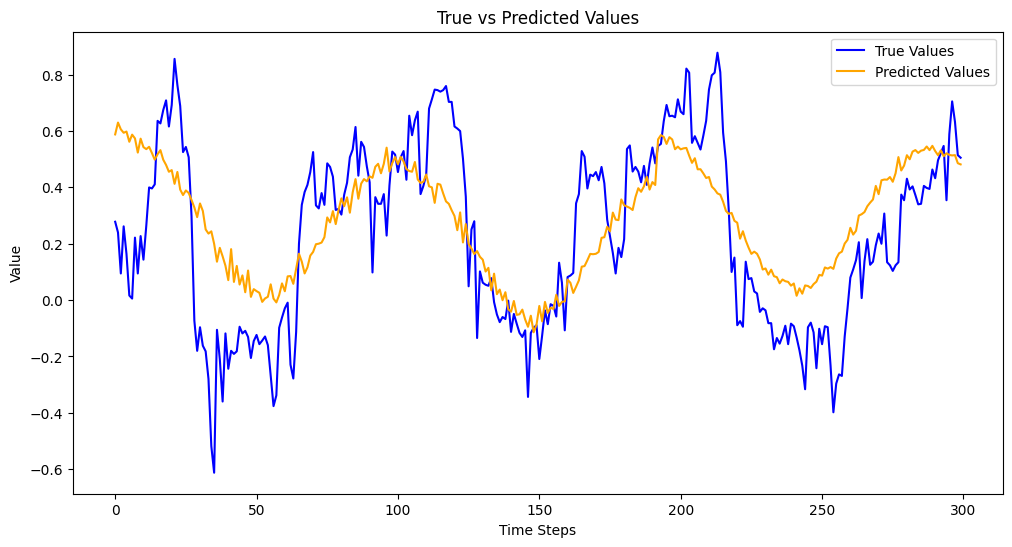

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(trues[:300, 2], label='True Values', color='blue')
plt.plot(preds[:300, 2], label='Predicted Values', color='orange')
plt.title('True vs Predicted Values')
plt.xlabel('Time Steps')
plt.ylabel('Value')
plt.legend()
plt.show()